# TunasMatch — Proyek Klasifikasi Tanaman

Klasifikasi Rekomendasi Jenis Tanaman Berdasarkan Kandungan Hara Tanah dan Kondisi Iklim Menggunakan K-Nearest Neighbors, Decision Tree, dan Logistic Regression

Notebook end-to-end: memahami data → EDA → preprocessing → nested CV/GridSearch → evaluasi → analisis → simpan model → inferensi. Seluruh angka berasal dari eksekusi. Edit identitas di `group_config.json`.

**Tidak memodifikasi dataset asli atau model utama saat Run All.** Training dijalankan ke folder audit sementara. `train.py` menyimpan alur yang sama agar notebook dan aplikasi tidak berbeda resep.

## 1. Persiapan
Jalankan `python -m pip install -r requirements-dev.txt` dahulu. Notebook dapat dibuka dari folder proyek atau parent workspace. Tidak memerlukan unduhan dataset.

In [1]:
from pathlib import Path
import sys, os, tempfile, inspect, json
import pandas as pd
import numpy as np
from IPython.display import display, Image, Markdown
root = Path.cwd()
if not (root / 'crop_core.py').exists():
    matches = [p.parent for p in root.glob('*/crop_core.py')]
    if matches:
        root = matches[0]
assert (root / 'crop_core.py').exists(), 'Buka notebook dari folder proyek TunasMatch atau parent workspace.'
sys.path.insert(0, str(root))
from crop_core import FEATURES, DISPLAY, SEED, load_dataset, read_json, predict_frame
from train import candidates, run_training
print('Seed final:', SEED)
display(read_json(root / 'group_config.json'))

Seed final: 2026


{'group_name': 'Kelompok 7',
 'class': 'TEK1302|Pembelajaran Mesin',
 'members': [{'name': 'Azaria Nur Febriasari',
   'nim': 'J0404241041',
   'task': 'Dataset, EDA, Preprocessing, dan Studi Literatur'},
  {'name': 'Radinal Avram Utama',
   'nim': 'J0404241161',
   'task': 'Pengembangan Model, Tuning, Nested CV, dan Evaluasi'},
  {'name': 'Mikhail Rafi Azka',
   'nim': 'J0404241168',
   'task': 'Implementasi Aplikasi TunasMatch, Dokumentasi, dan Video Demo'}],
 'deployment_url': '',
 'video_url': '',
 'note': 'Kelompok 7 - TunasMatch'}

## 2. Loading dan audit dataset
Satu baris adalah satu contoh berlabel, bukan bukti pengukuran lahan unik. NPK memakai skala sumber; periode rainfall belum terverifikasi.

In [2]:
df = load_dataset()
print('Bentuk:', df.shape)
display(df.head())
df.info()
display(df.describe().T)

Bentuk: (2200, 8)


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


<class 'pandas.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   str    
dtypes: float64(4), int64(3), str(1)
memory usage: 153.0 KB


,count,mean,std,min,25%,50%,75%,max
N,2200.0,50.551818,36.917334,0.000000,21.000000,37.000000,84.250000,140.000000
P,2200.0,53.362727,32.985883,5.000000,28.000000,51.000000,68.000000,145.000000
K,2200.0,48.149091,50.647931,5.000000,20.000000,32.000000,49.000000,205.000000
temperature,2200.0,25.616244,5.063749,8.825675,22.769375,25.598693,28.561654,43.675493
humidity,2200.0,71.481779,22.263812,14.258040,60.261953,80.473146,89.948771,99.981876
ph,2200.0,6.469480,0.773938,3.504752,5.971693,6.425045,6.923643,9.935091
rainfall,2200.0,103.463655,54.958389,20.211267,64.551686,94.867624,124.267508,298.560117


In [3]:
display(df.isna().sum().rename('missing'))
print('Duplikat:', df.duplicated().sum())
display(df.label.value_counts().sort_index())
assert df.shape == (2200, 8)
assert (df.label.value_counts() == 100).all()

N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
Name: missing, dtype: int64

Duplikat: 0


label
apple          100
banana         100
blackgram      100
chickpea       100
coconut        100
coffee         100
cotton         100
grapes         100
jute           100
kidneybeans    100
lentil         100
maize          100
mango          100
mothbeans      100
mungbean       100
muskmelon      100
orange         100
papaya         100
pigeonpeas     100
pomegranate    100
rice           100
watermelon     100
Name: count, dtype: int64

**Interpretasi:** data 22 kelas seimbang; tidak perlu SMOTE. Tidak ada nilai kosong atau duplikat sehingga tidak melakukan imputasi/deduplikasi palsu. Ketidakadaan missing bukan bukti data lapangan berkualitas sempurna.

## 3. Pisahkan X/y dan split 80:20 stratified
Test tidak dipakai menghitung scaler, memilih parameter, atau menentukan pemenang. Indeks akan disimpan oleh eksperimen. Baseline eksploratif seed 42 pernah diperiksa; final memakai seed 2026 tetap, bukan mencari seed terbaik.

In [4]:
from sklearn.model_selection import train_test_split
ids_train, ids_test = train_test_split(np.arange(len(df)), test_size=.2, random_state=SEED, stratify=df.label)
X_train = df.iloc[ids_train][FEATURES]
y_train = df.iloc[ids_train].label
X_test = df.iloc[ids_test][FEATURES]
y_test = df.iloc[ids_test].label
print('Training:', len(X_train), 'Test:', len(X_test))
display(pd.DataFrame({'train':y_train.value_counts(), 'test':y_test.value_counts()}).sort_index())
assert not set(ids_train) & set(ids_test)

Training: 1760 Test: 440


,train,test
label,,
apple,80,20
banana,80,20
blackgram,80,20
chickpea,80,20
coconut,80,20
coffee,80,20
cotton,80,20
grapes,80,20
jute,80,20


## 4. EDA training sebelum model
Grafik fitur memakai training saja; distribusi kelas sumber adalah audit. Setiap grafik berikut diberi penjelasan, bukan hanya gambar.

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
X_train.hist(figsize=(12, 7), bins=20, color='#27835d')
plt.suptitle('Histogram tujuh fitur training'); plt.tight_layout(); plt.show()
display(X_train.corr().round(3))

C:\Users\user\AppData\Local\Temp\ipykernel_15412\3165172045.py:4: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.suptitle('Histogram tujuh fitur training'); plt.tight_layout(); plt.show()


,N,P,K,temperature,humidity,ph,rainfall
N,1.000,-0.227,-0.136,0.028,0.193,0.092,0.055
P,-0.227,1.000,0.737,-0.114,-0.120,-0.139,-0.062
K,-0.136,0.737,1.000,-0.142,0.190,-0.166,-0.053
temperature,0.028,-0.114,-0.142,1.000,0.207,-0.034,-0.038
humidity,0.193,-0.120,0.190,0.207,1.000,-0.007,0.095
ph,0.092,-0.139,-0.166,-0.034,-0.007,1.000,-0.102
rainfall,0.055,-0.062,-0.053,-0.038,0.095,-0.102,1.000


**Baca histogram:** skala NPK, hujan dan pH berbeda; beberapa distribusi multimodal karena gabungan 22 tanaman. StandardScaler bukan pengubah ke 0–1. Korelasi hanya hubungan linear, bukan penyebab atau korelasi label numerik yang bermakna ordinal.

In [6]:
q1, q3 = X_train.quantile(.25), X_train.quantile(.75)
iqr = q3-q1
display(((X_train < q1-1.5*iqr) | (X_train > q3+1.5*iqr)).sum().rename('ditandai_IQR'))
print('Tidak otomatis menghapus nilai yang ditandai.')

N                0
P              110
K              160
temperature     73
humidity        26
ph              48
rainfall        87
Name: ditandai_IQR, dtype: int64

Tidak otomatis menghapus nilai yang ditandai.


**Baca outlier:** angka ekstrem perlu dilihat per kelas; K tinggi terkumpul pada apel/anggur dalam sumber. Tidak otomatis salah, tetapi juga tidak mengklaim seluruhnya terbukti valid secara agronomis. Kode tidak membuang data berdasarkan IQR.

## 5. Model, pipeline dan ruang GridSearch
KNN dan LR: scaler → classifier. DT: classifier tanpa scaler. Encoder di-fit dari label training; label bukan fitur. Pipeline di-fit ulang dalam setiap fold untuk mencegah leakage.

In [7]:
for name, (pipeline, grid) in candidates().items():
    print(name)
    display(pipeline)
    display(grid)

KNN


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value

{'model__n_neighbors': [3, 5, 7, 9, 11],
 'model__weights': ['uniform', 'distance'],
 'model__p': [1, 2]}

Decision Tree


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",2026
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andrig

{'model__max_depth': [5, 8, 12, None],
 'model__min_samples_leaf': [1, 2, 4],
 'model__criterion': ['gini', 'entropy']}

Logistic Regression


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaler', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",3000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L

{'model__C': [0.01, 0.1, 1, 10, 100]}

## 6. Jalankan eksperimen lengkap
Outer StratifiedKFold=5, inner GridSearchCV=3 fold pada training; mean outer macro-F1 memilih keluarga model. Kemudian final GridSearch=5 fold pada seluruh training. Test dihitung setelah pilihan ditulis. SD antarfold bukan confidence interval; keunggulan sangat tipis tidak signifikan secara otomatis.

Kode lengkap dapat dibaca pada cell berikut dan `train.py`. Output audit tidak menimpa artefak proyek utama.

In [8]:
print(inspect.getsource(run_training))

def run_training(output_dir=None):
    out = Path(output_dir) if output_dir else ROOT
    for folder in ["models", "results", "plots", "examples", "data"]:
        (out / folder).mkdir(parents=True, exist_ok=True)
    res, plots = out / "results", out / "plots"
    start = time.perf_counter()
    df = load_dataset()
    ids = np.arange(len(df))
    train_ids, test_ids = train_test_split(ids, test_size=.2, random_state=SEED, stratify=df.label)
    tr, te = df.iloc[train_ids].copy(), df.iloc[test_ids].copy()
    x, xt = tr[FEATURES], te[FEATURES]
    encoder = LabelEncoder().fit(tr.label)
    y, yt = encoder.transform(tr.label), encoder.transform(te.label)
    labels = encoder.classes_.tolist()
    write_json(res / "split_indices.json", {"seed": SEED, "train": train_ids.tolist(), "test": test_ids.tolist()})
    write_json(res / "label_mapping.json", {str(i): label for i, label in enumerate(labels)})
    write_json(res / "data_profile.json", {"shape": list(df.shape), "dtypes": {c: str(t) 

In [9]:
temp_parent = Path(os.environ.get('LOCALAPPDATA', str(root))) / 'Temp' / 'opencode'
temp_parent.mkdir(parents=True, exist_ok=True)
audit = tempfile.TemporaryDirectory(prefix='crop_notebook_', dir=temp_parent)
RUN_DIR = Path(audit.name)
summary = run_training(output_dir=RUN_DIR)
display(summary)

Nested CV: KNN


Nested CV: Decision Tree


Nested CV: Logistic Regression


              model  cv_f1_macro_mean  cv_f1_macro_std  cv_accuracy_mean  cv_train_f1_mean   cv_gap  train_accuracy  train_f1_macro  accuracy  precision_macro  recall_macro  f1_macro  n_correct  n_test
Logistic Regression          0.985205         0.004202          0.985227          0.993320 0.008115        0.992614        0.992609  0.968182         0.969044      0.968182  0.967840        426     440
      Decision Tree          0.985203         0.003080          0.985227          0.997441 0.012238        0.997727        0.997726  0.986364         0.986947      0.986364  0.986338        434     440
                KNN          0.982356         0.003747          0.982386          1.000000 0.017644        1.000000        1.000000  0.970455         0.974889      0.970455  0.969856        427     440


Selected: Logistic Regression | output: C:\Users\user\AppData\Local\Temp\opencode\crop_notebook_lxhdmgn3


{'title': 'Klasifikasi Rekomendasi Jenis Tanaman Berdasarkan Kandungan Hara Tanah dan Kondisi Iklim Menggunakan K-Nearest Neighbors, Decision Tree, dan Logistic Regression',
 'selected_model': 'Logistic Regression',
 'seed': 2026,
 'n_source': 2200,
 'n_train': 1760,
 'n_test': 440,
 'n_features': 7,
 'n_classes': 22,
 'selected_cv': {'model': 'Logistic Regression',
  'cv_f1_macro_mean': 0.9852053635370437,
  'cv_f1_macro_std': 0.004201507527686479,
  'cv_accuracy_mean': 0.9852272727272726,
  'cv_train_f1_mean': 0.9933202806943587,
  'cv_gap': 0.008114917157315004},
 'selected_test': {'train_accuracy': 0.9926136363636363,
  'train_f1_macro': 0.9926093501395129,
  'accuracy': 0.9681818181818181,
  'precision_macro': 0.9690435196117014,
  'recall_macro': 0.9681818181818183,
  'f1_macro': 0.9678396378974042,
  'n_correct': 426.0,
  'n_test': 440.0},
 'best_params': {'model__C': 100},
 'model_sha256': '468f0e92676c2d08a44ee7443138f377e91c924ae6bf8821ad0267355e5caac5',
 'dataset_sha256': '5

## 7. Baca hasil EDA tersimpan
Distribusi kelas: sama-sama 100. Boxplot: tinjau nilai ekstrem, jangan hapus otomatis. Scatter: tanaman dapat bertumpang tindih pada dua fitur; classifier memakai tujuh fitur.

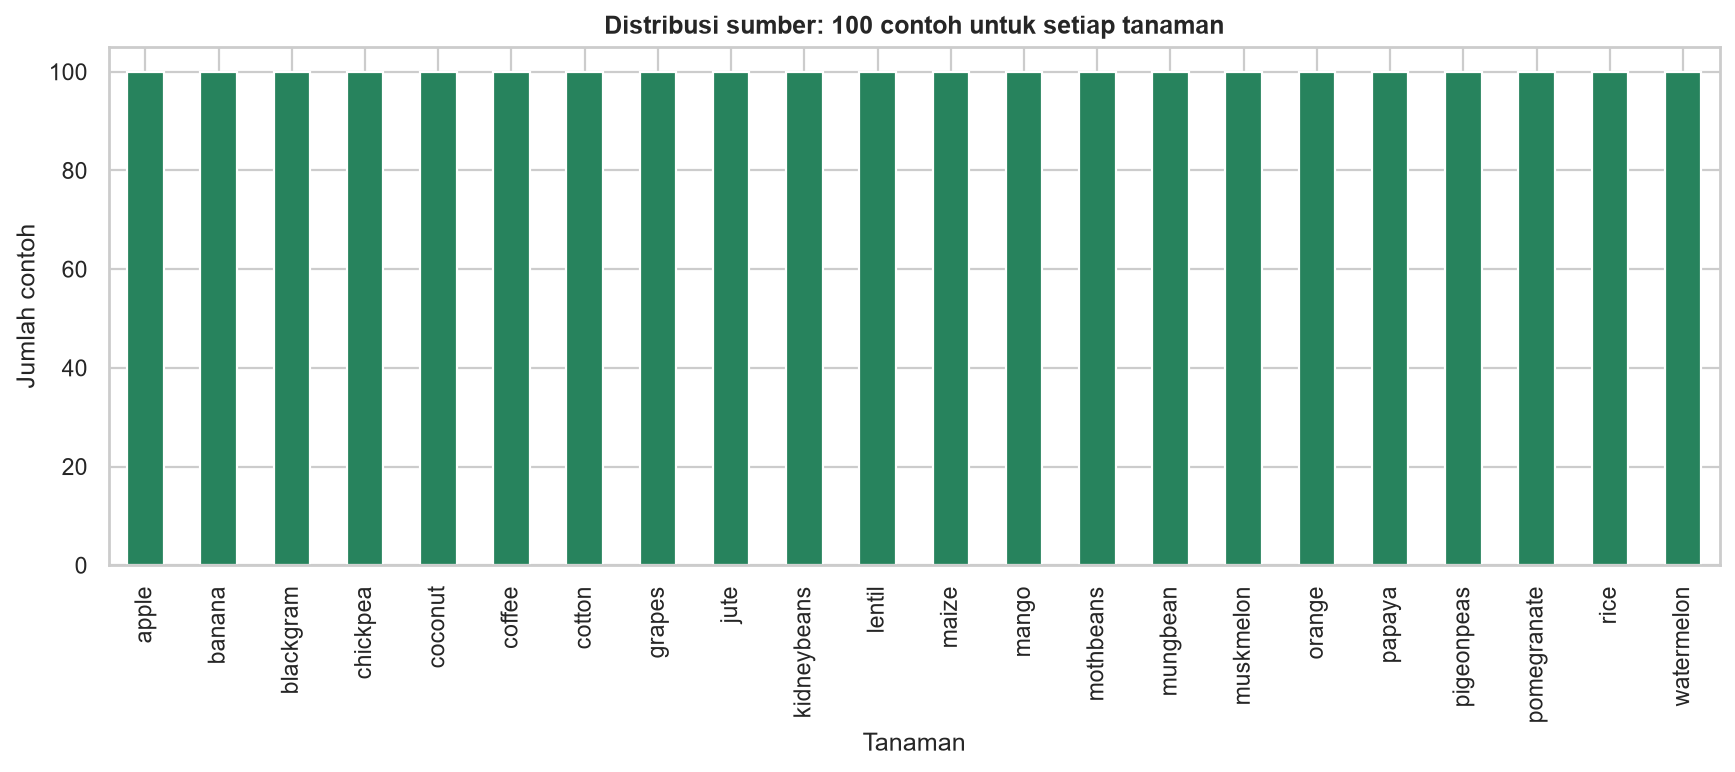

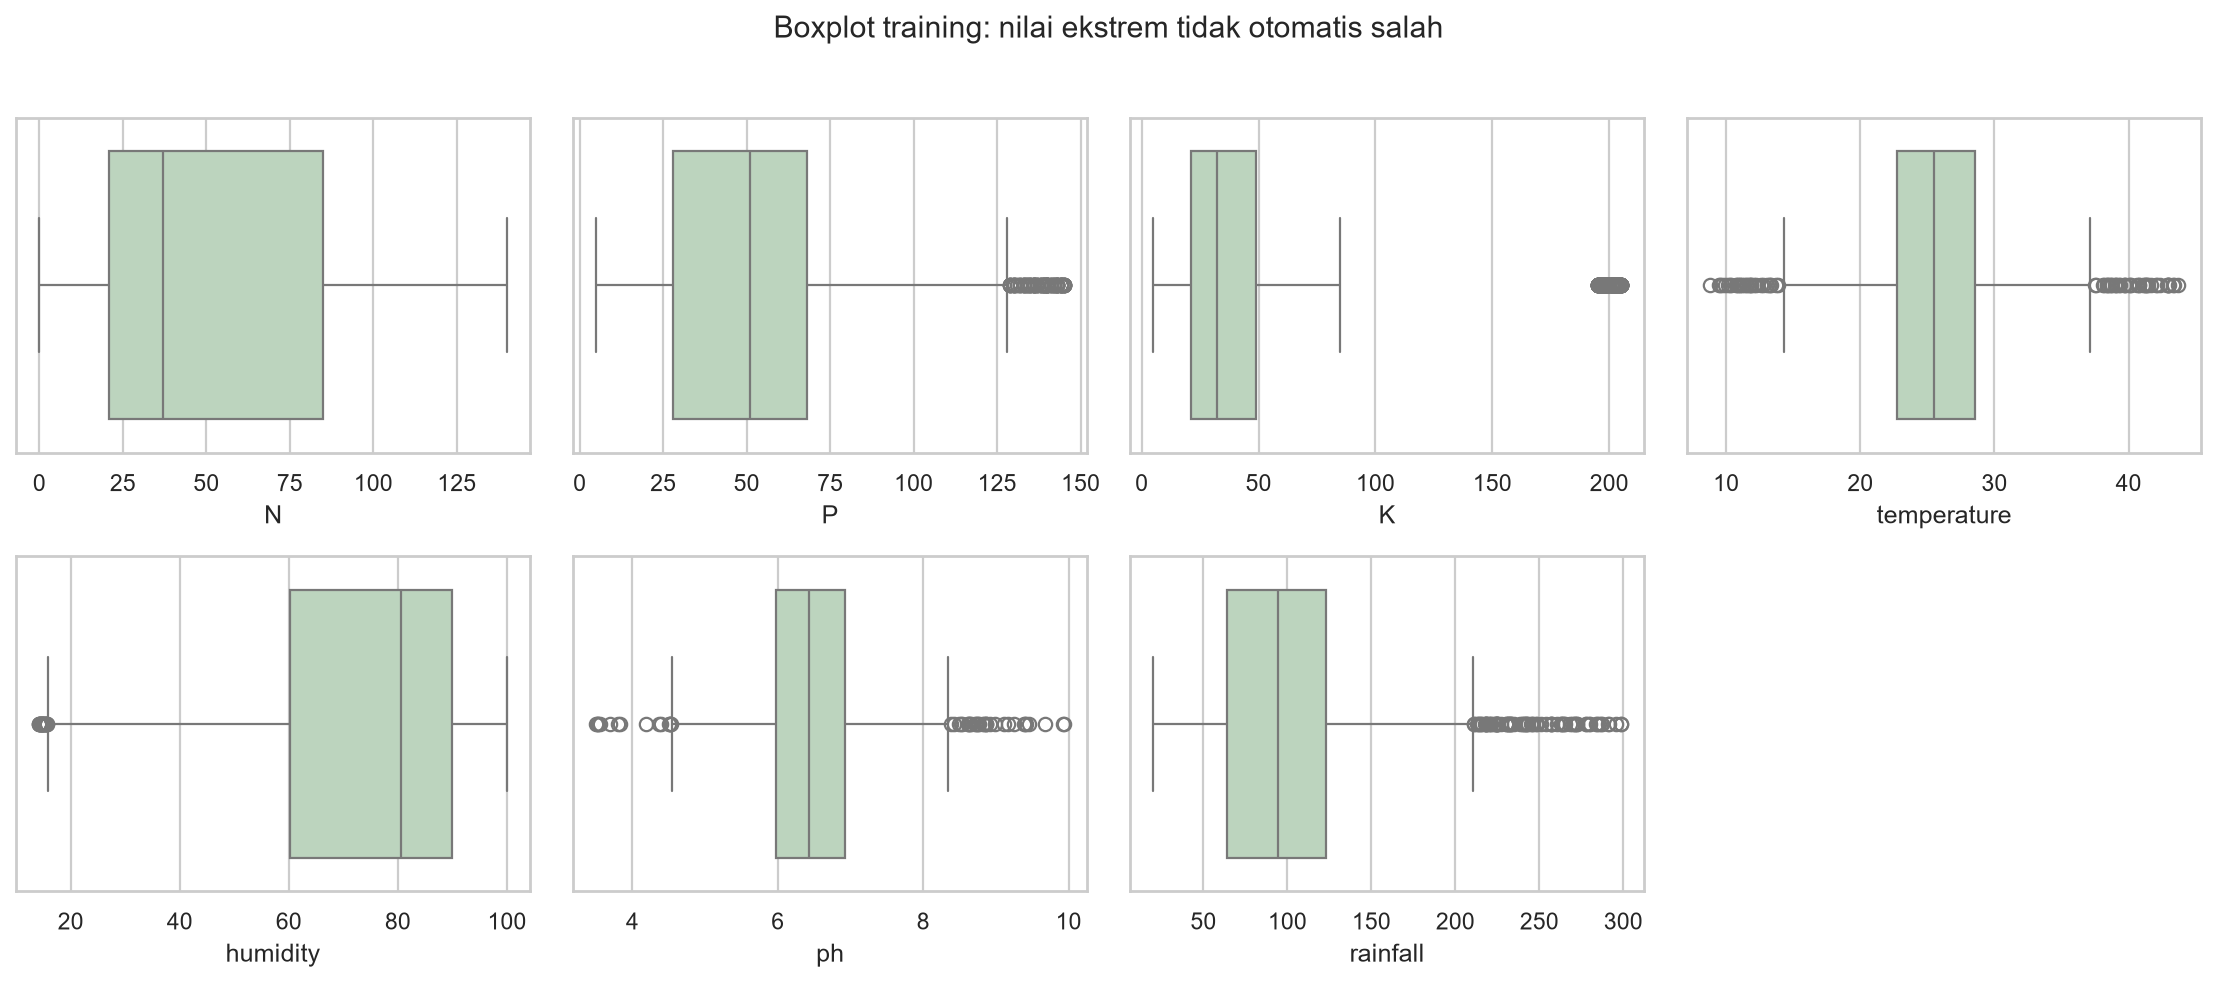

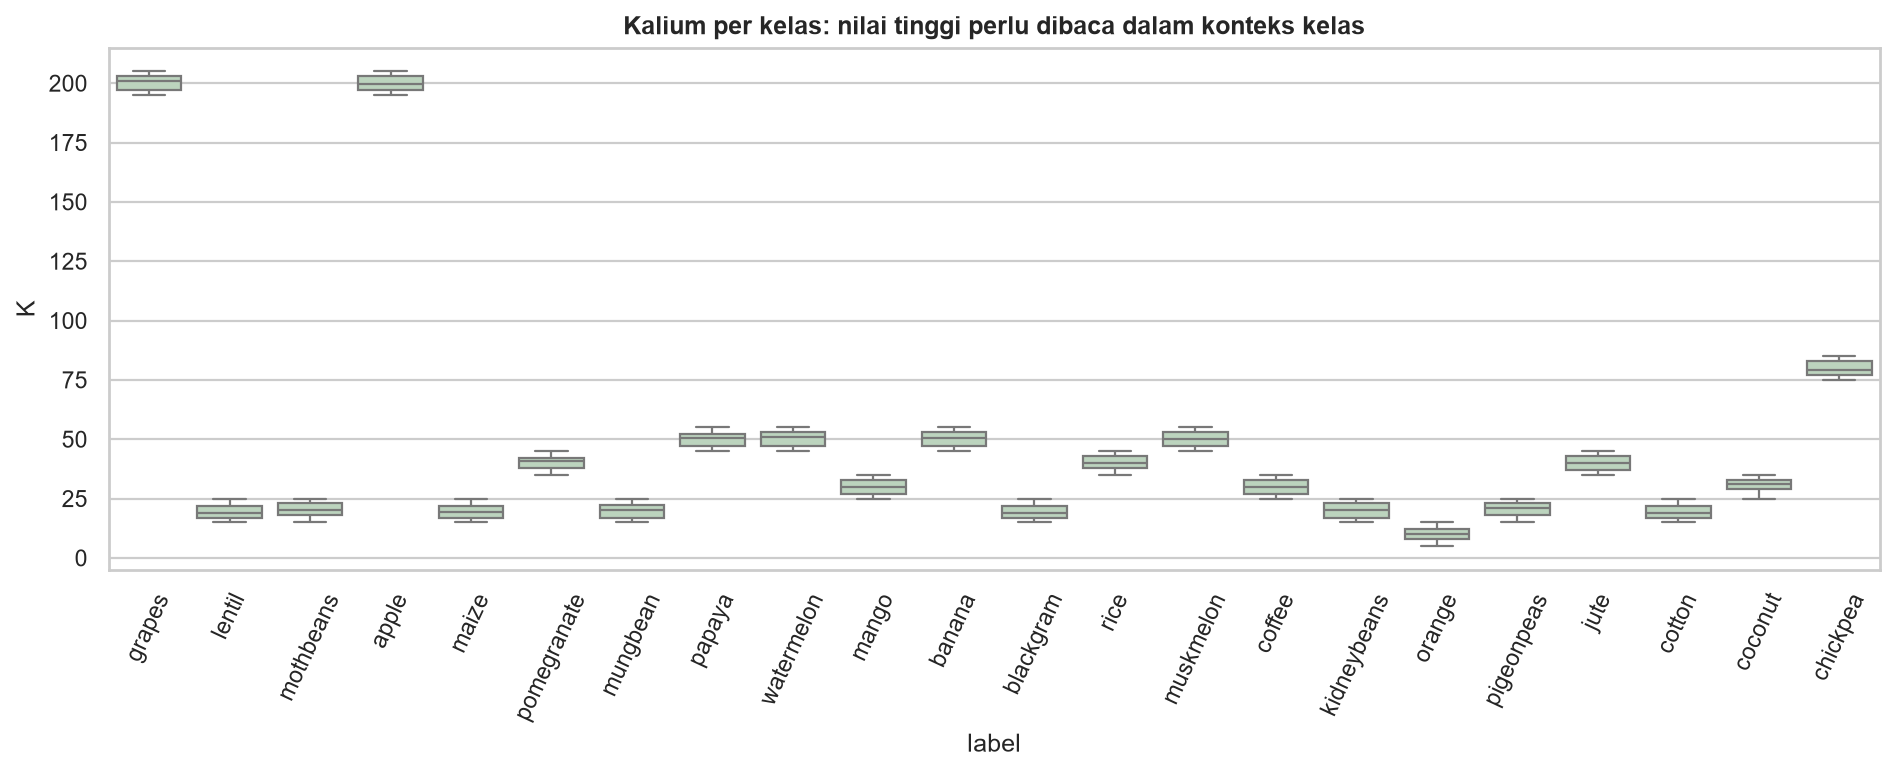

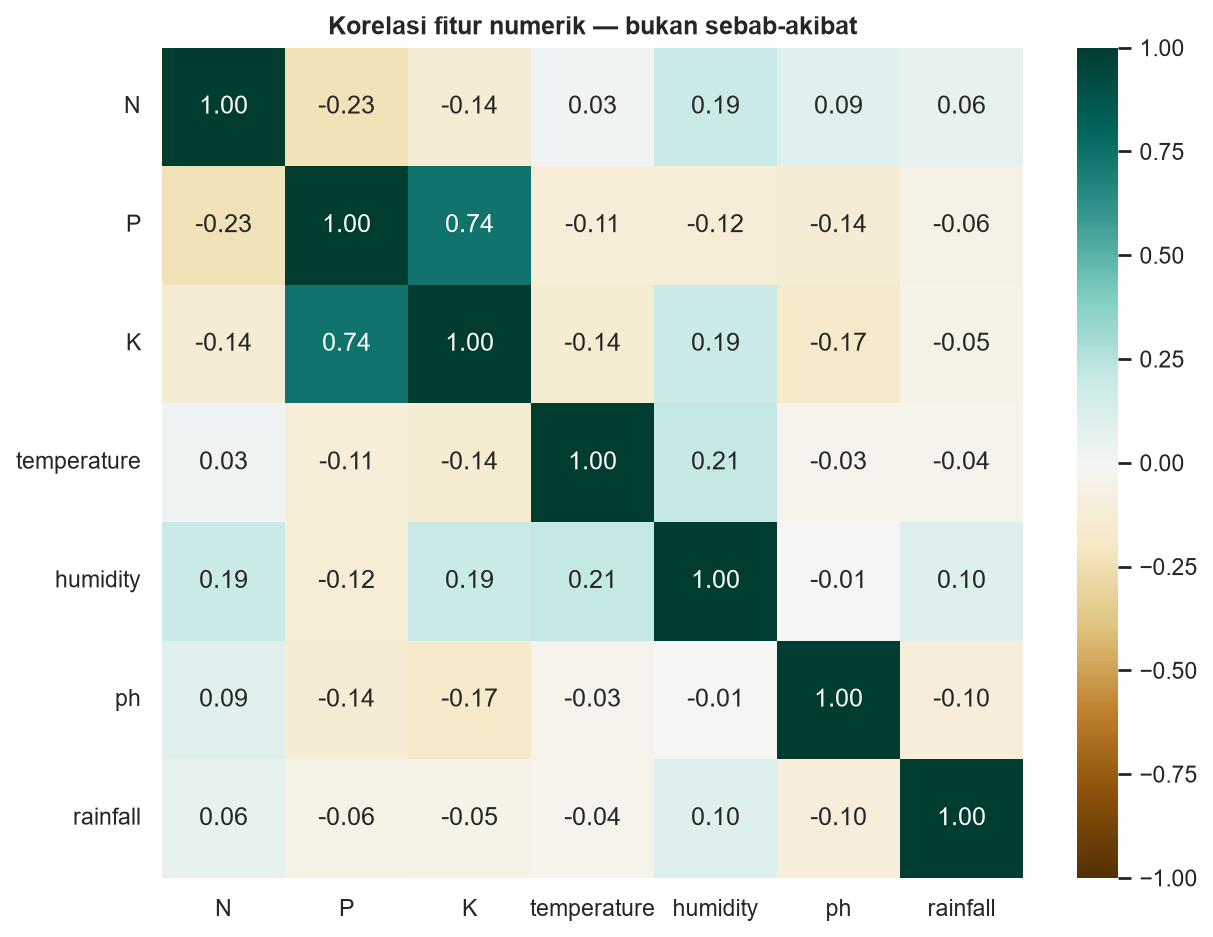

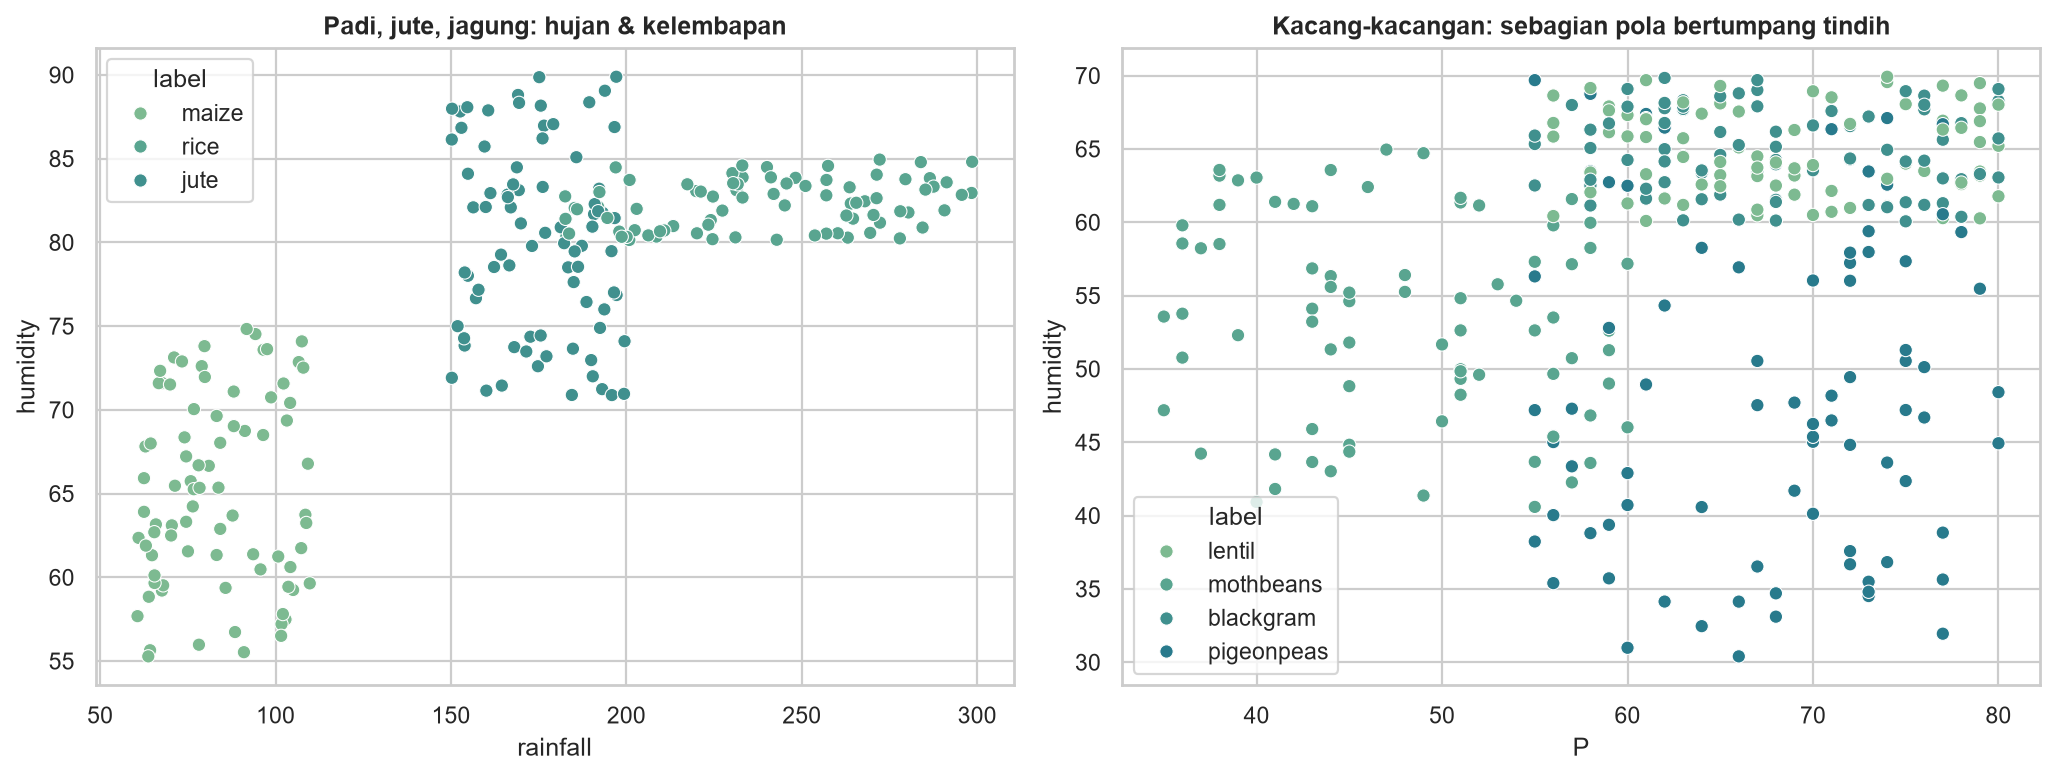

In [10]:
for name in ['distribusi_kelas.png', 'boxplot.png', 'kalium_per_kelas.png', 'korelasi.png', 'scatter_kemiripan.png']:
    display(Image(filename=str(RUN_DIR / 'plots' / name)))

## 8. Validasi, tuning dan ujian akhir
Pilih model berdasarkan outer CV, bukan test. Skor final GridSearch cenderung optimistis untuk kandidat pemenang tuning; jangan menggantikannya dengan outer score. Seluruh 22 label mendapat bobot sama pada macro-F1.

In [11]:
cv = pd.read_csv(RUN_DIR / 'results/cv_comparison.csv')
test = pd.read_csv(RUN_DIR / 'results/test_comparison.csv')
display(cv)
display(read_json(RUN_DIR / 'results/tuning.json'))
display(read_json(RUN_DIR / 'results/selection_before_test.json'))
display(test)

,model,cv_f1_macro_mean,cv_f1_macro_std,cv_accuracy_mean,cv_train_f1_mean,cv_gap
0,Logistic Regression,0.985205,0.004202,0.985227,0.993320,0.008115
1,Decision Tree,0.985203,0.003080,0.985227,0.997441,0.012238
2,KNN,0.982356,0.003747,0.982386,1.000000,0.017644


{'KNN': {'best_params': {'model__n_neighbors': 5,
   'model__p': 1,
   'model__weights': 'distance'},
  'inner_training_cv_score': 0.982367201033329,
  'n_candidates': 20},
 'Decision Tree': {'best_params': {'model__criterion': 'gini',
   'model__max_depth': 12,
   'model__min_samples_leaf': 1},
  'inner_training_cv_score': 0.9886077923571456,
  'n_candidates': 24},
 'Logistic Regression': {'best_params': {'model__C': 100},
  'inner_training_cv_score': 0.984076958562684,
  'n_candidates': 5}}

{'selected_model': 'Logistic Regression',
 'criterion': 'Mean outer nested-CV macro-F1 terbesar; tie: SD terkecil lalu nama alfabetis.',
 'selected_at_utc': '2026-11-23T16:11:56.713599+00:00',
 'test_used_for_selection': False,
 'seed': 2026,
 'protocol_note': 'Baseline eksploratif seed=42 pernah diperiksa sebelum paket ini. Eksperimen final menggunakan seed=2026 yang ditetapkan di kode, tanpa mencoba seed demi skor. Tidak ada klaim blind/preregistered study.'}

,model,train_accuracy,train_f1_macro,accuracy,precision_macro,recall_macro,f1_macro,n_correct,n_test
0,KNN,1.000000,1.000000,0.970455,0.974889,0.970455,0.969856,427,440
1,Decision Tree,0.997727,0.997726,0.986364,0.986947,0.986364,0.986338,434,440
2,Logistic Regression,0.992614,0.992609,0.968182,0.969044,0.968182,0.967840,426,440


Model aktif: Logistic Regression
Selisih dua CV teratas: 2.212874596008163e-06
Test tertinggi: Decision Tree


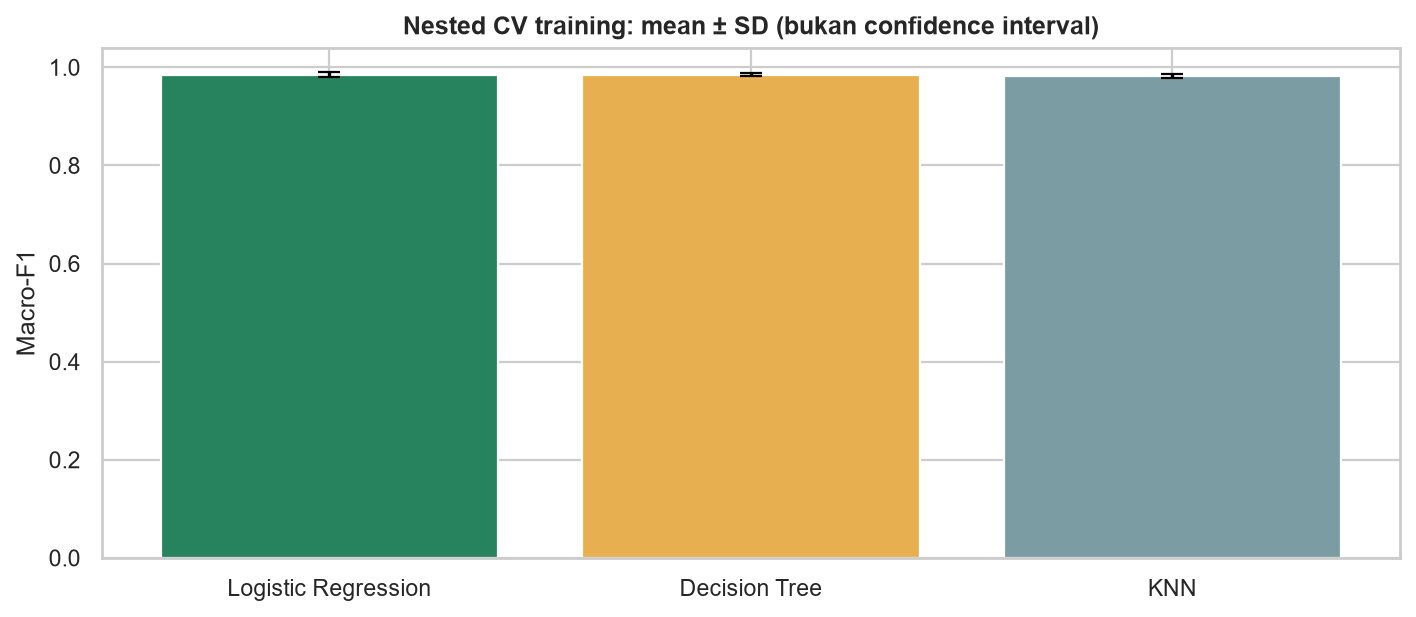

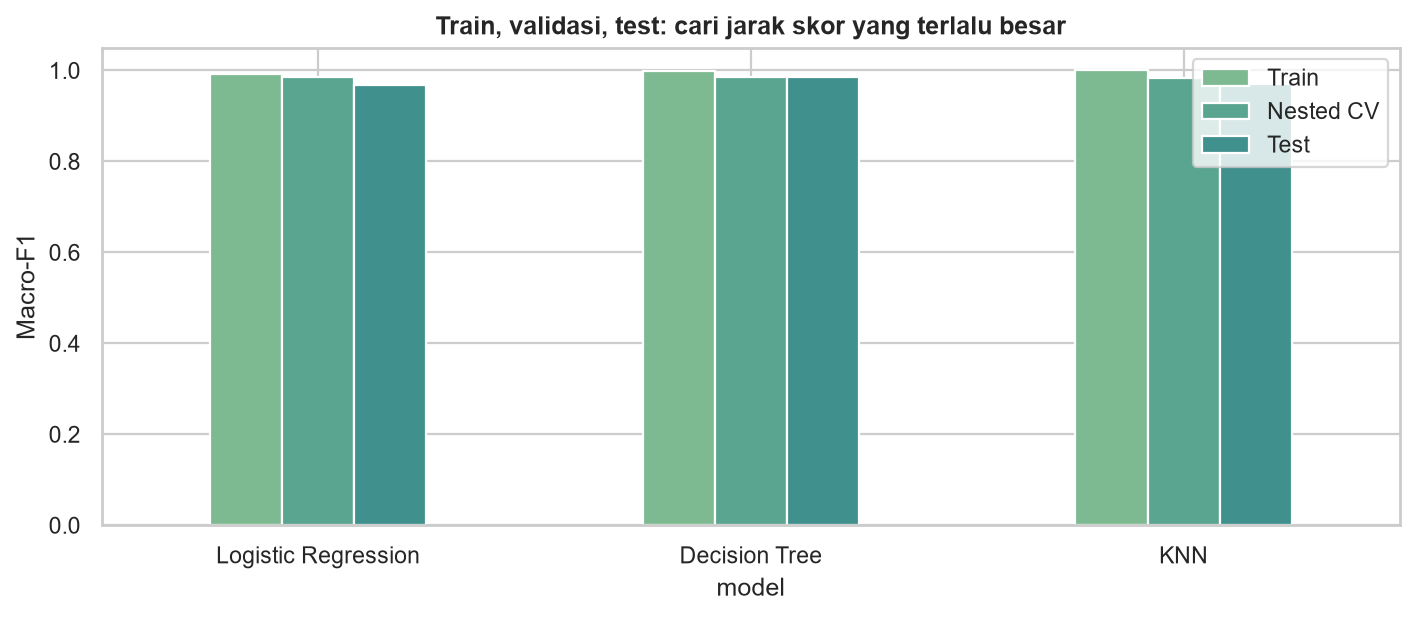

In [12]:
best = summary['selected_model']
print('Model aktif:', best)
print('Selisih dua CV teratas:', cv.iloc[0].cv_f1_macro_mean - cv.iloc[1].cv_f1_macro_mean)
print('Test tertinggi:', test.sort_values('f1_macro', ascending=False).iloc[0].model)
display(Image(filename=str(RUN_DIR / 'plots/perbandingan_cv.png')))
display(Image(filename=str(RUN_DIR / 'plots/train_cv_test.png')))

**Interpretasi:** LR dan DT hampir seri pada validasi; aturan tetap memilih mean tertinggi. DT unggul di test, tetapi tidak dipakai memilih ulang. KNN distance dapat memberi train=1 karena titik menjadi tetangga dirinya. Skor test tinggi tidak membuktikan generalisasi ke Indonesia.

## 9. Confusion matrix dan kesalahan tiap kelas
Baris=aktual, kolom=prediksi; diagonal benar. Periksa arah pasangan, bukan menyebut semua kesalahan kacang-kacangan tanpa membaca hasil.

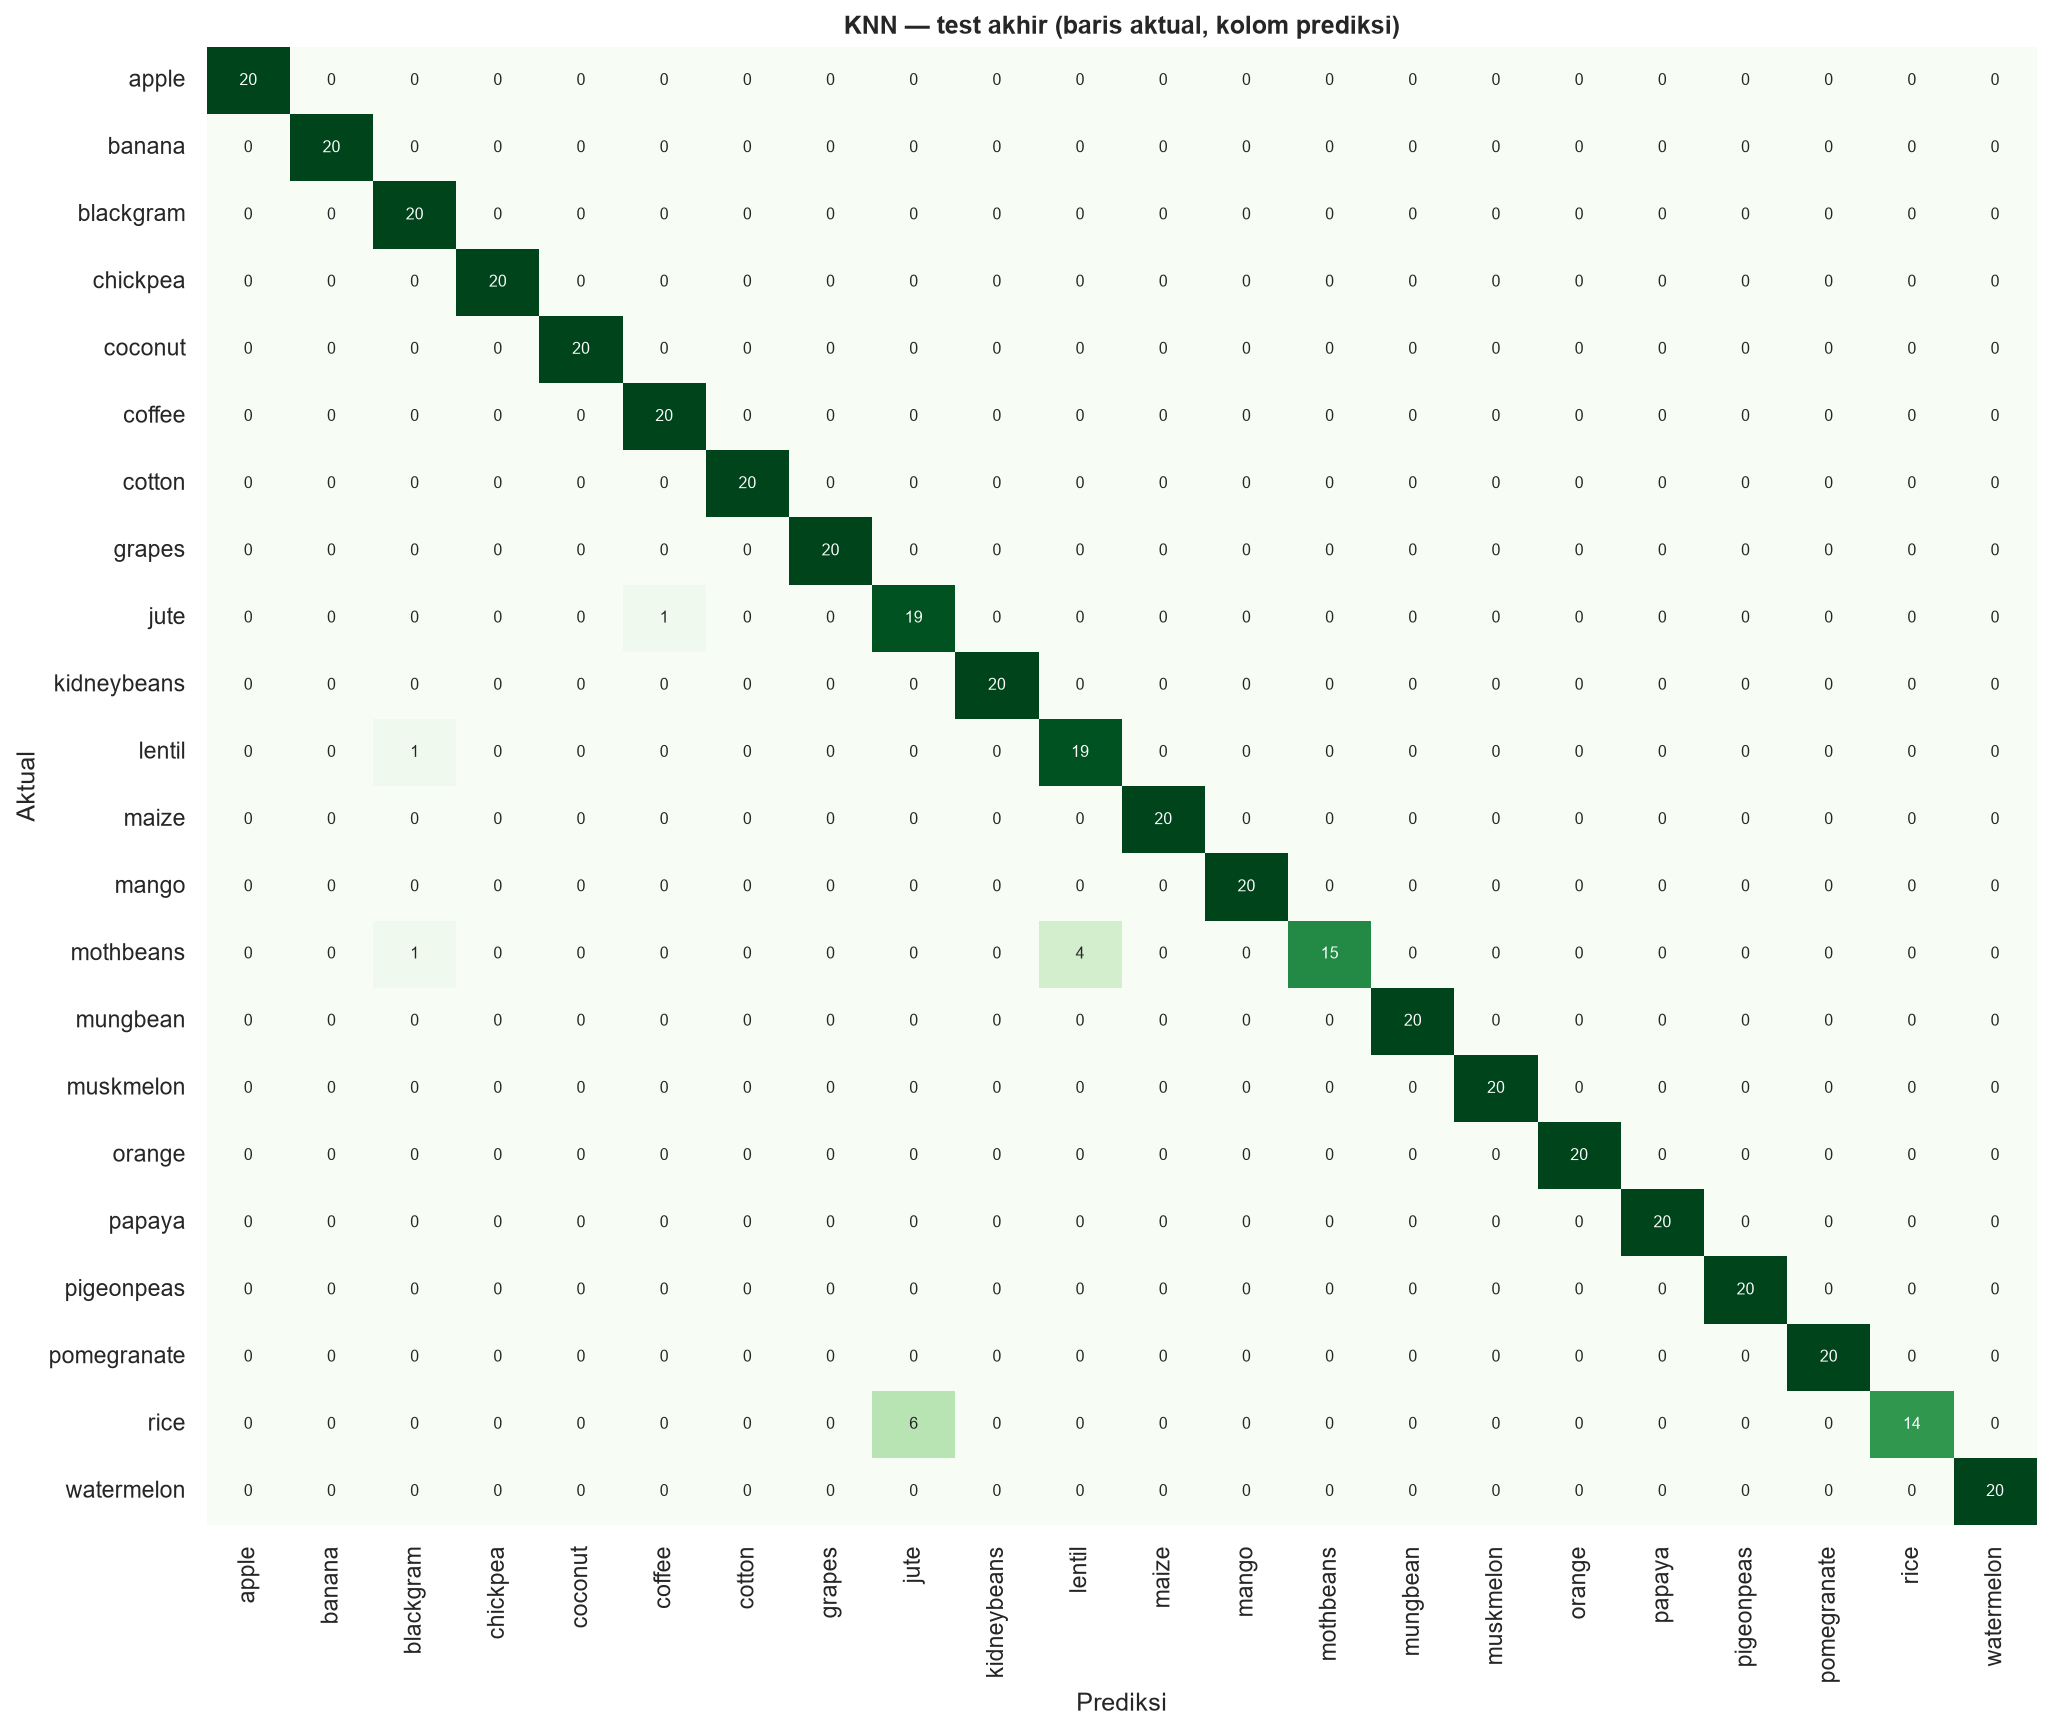

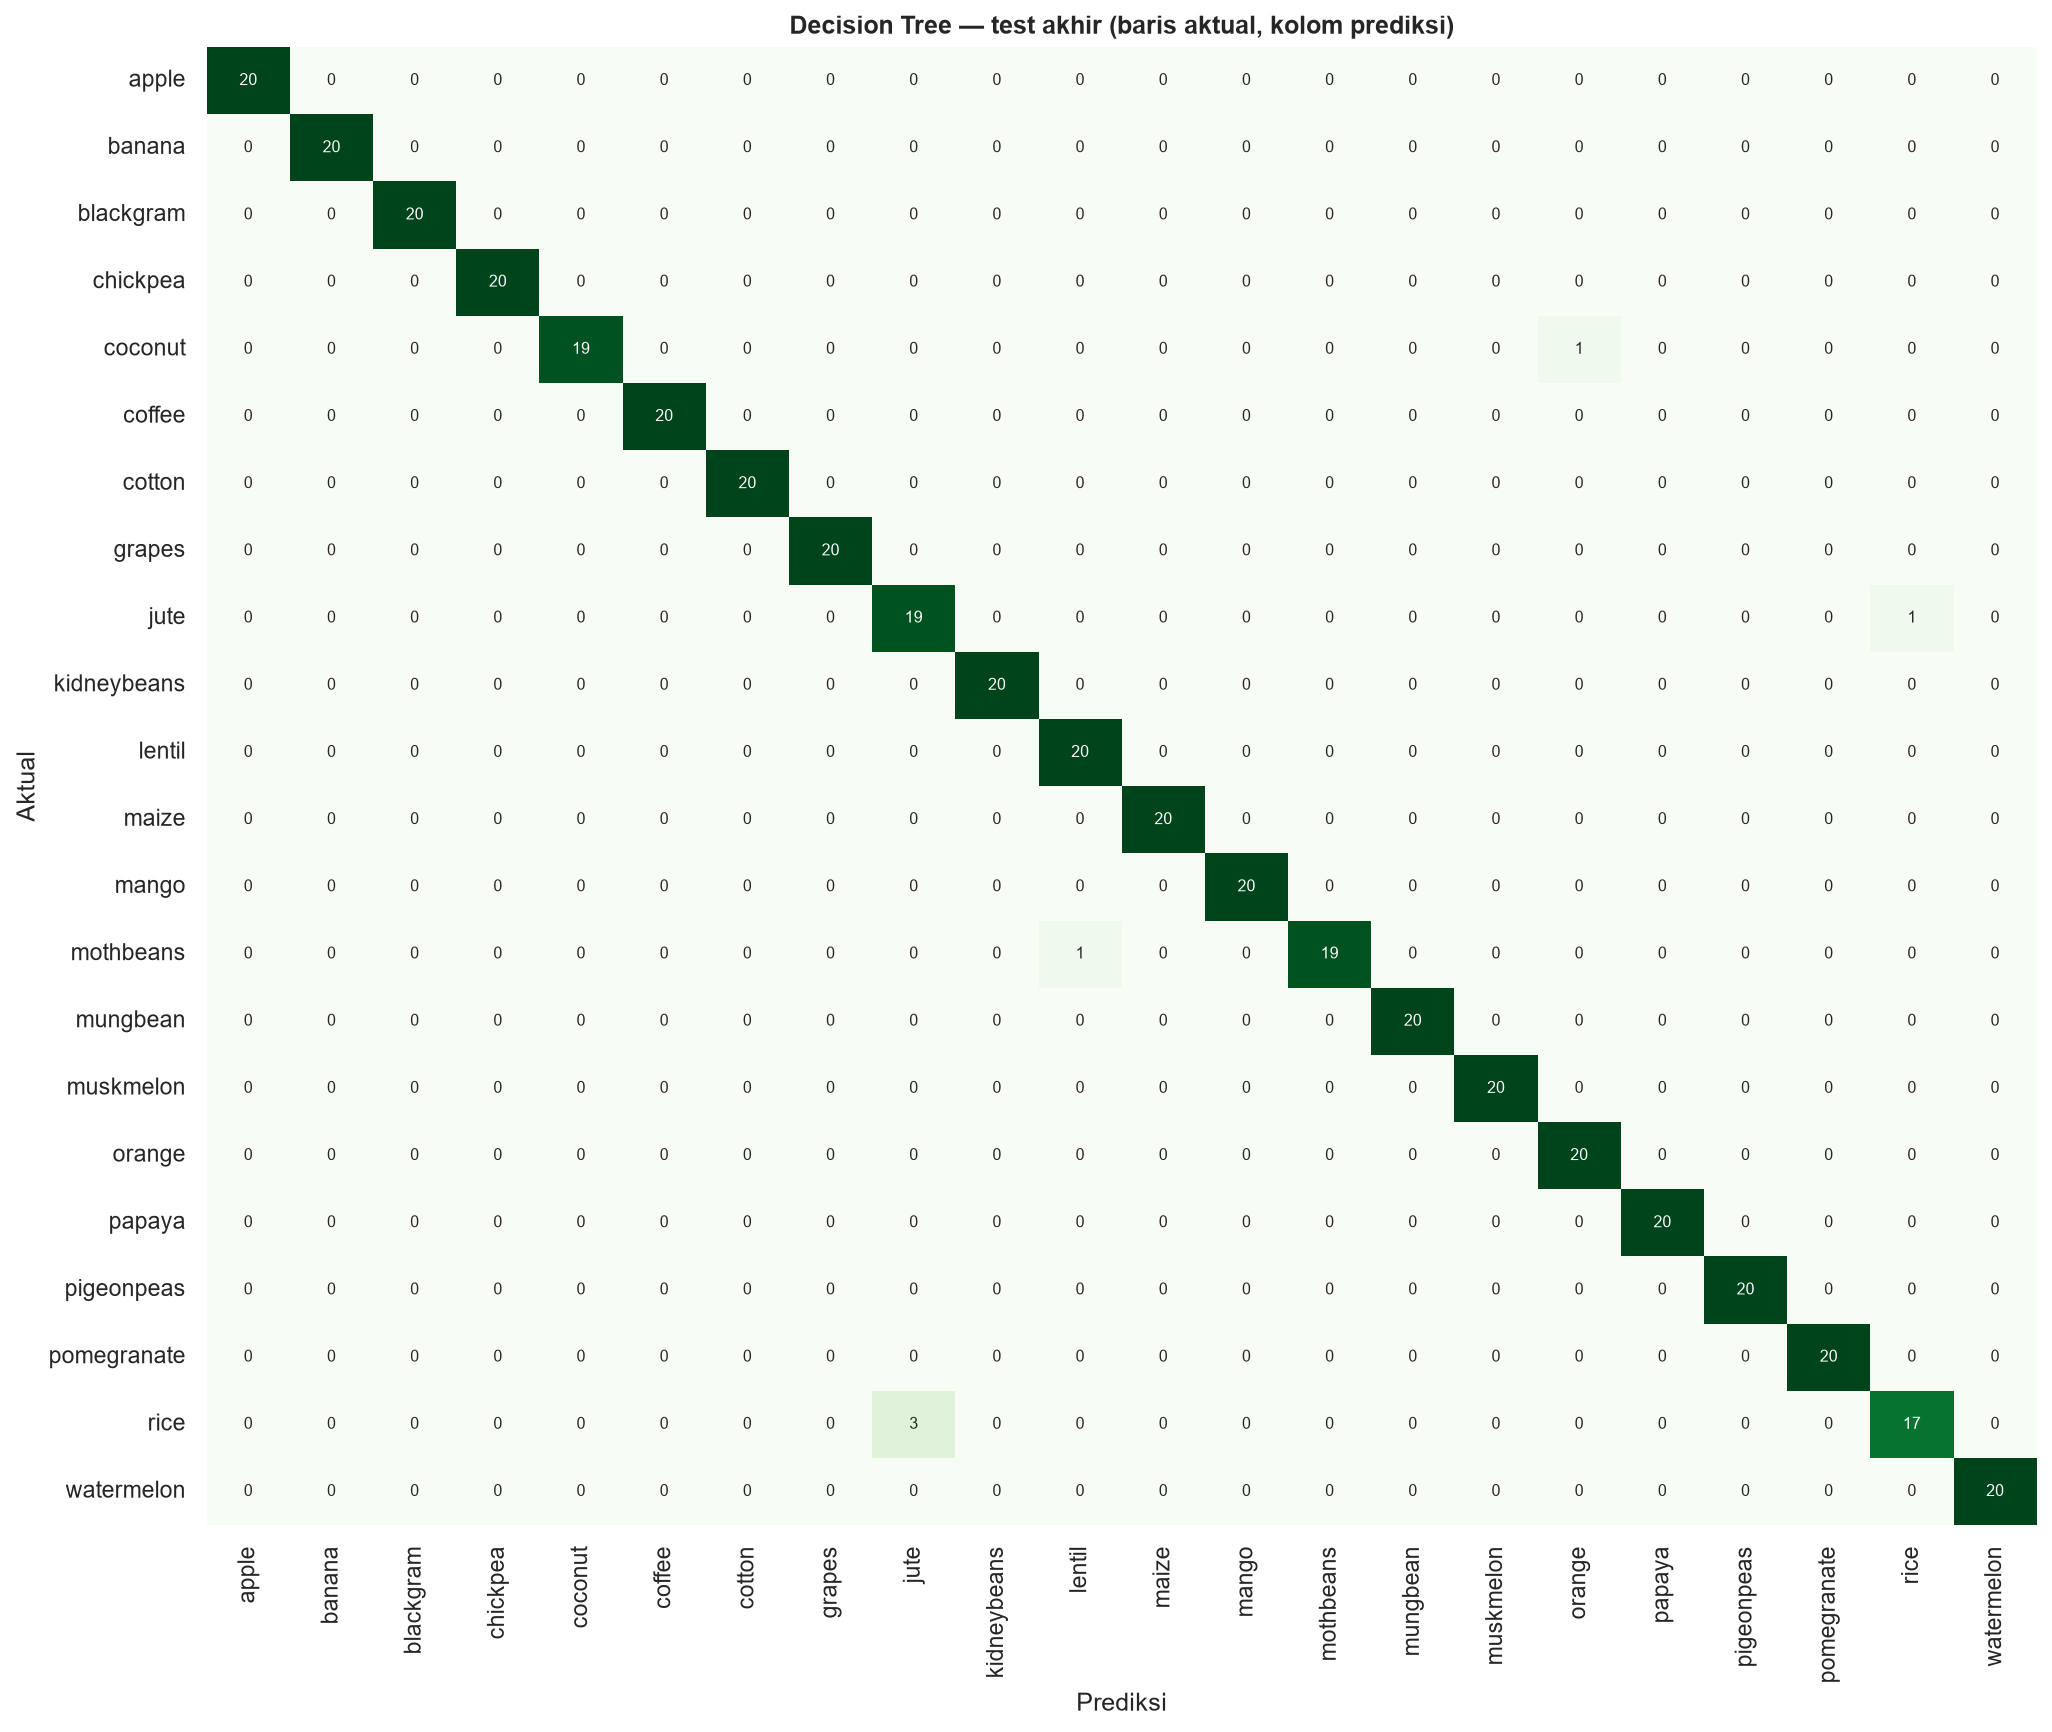

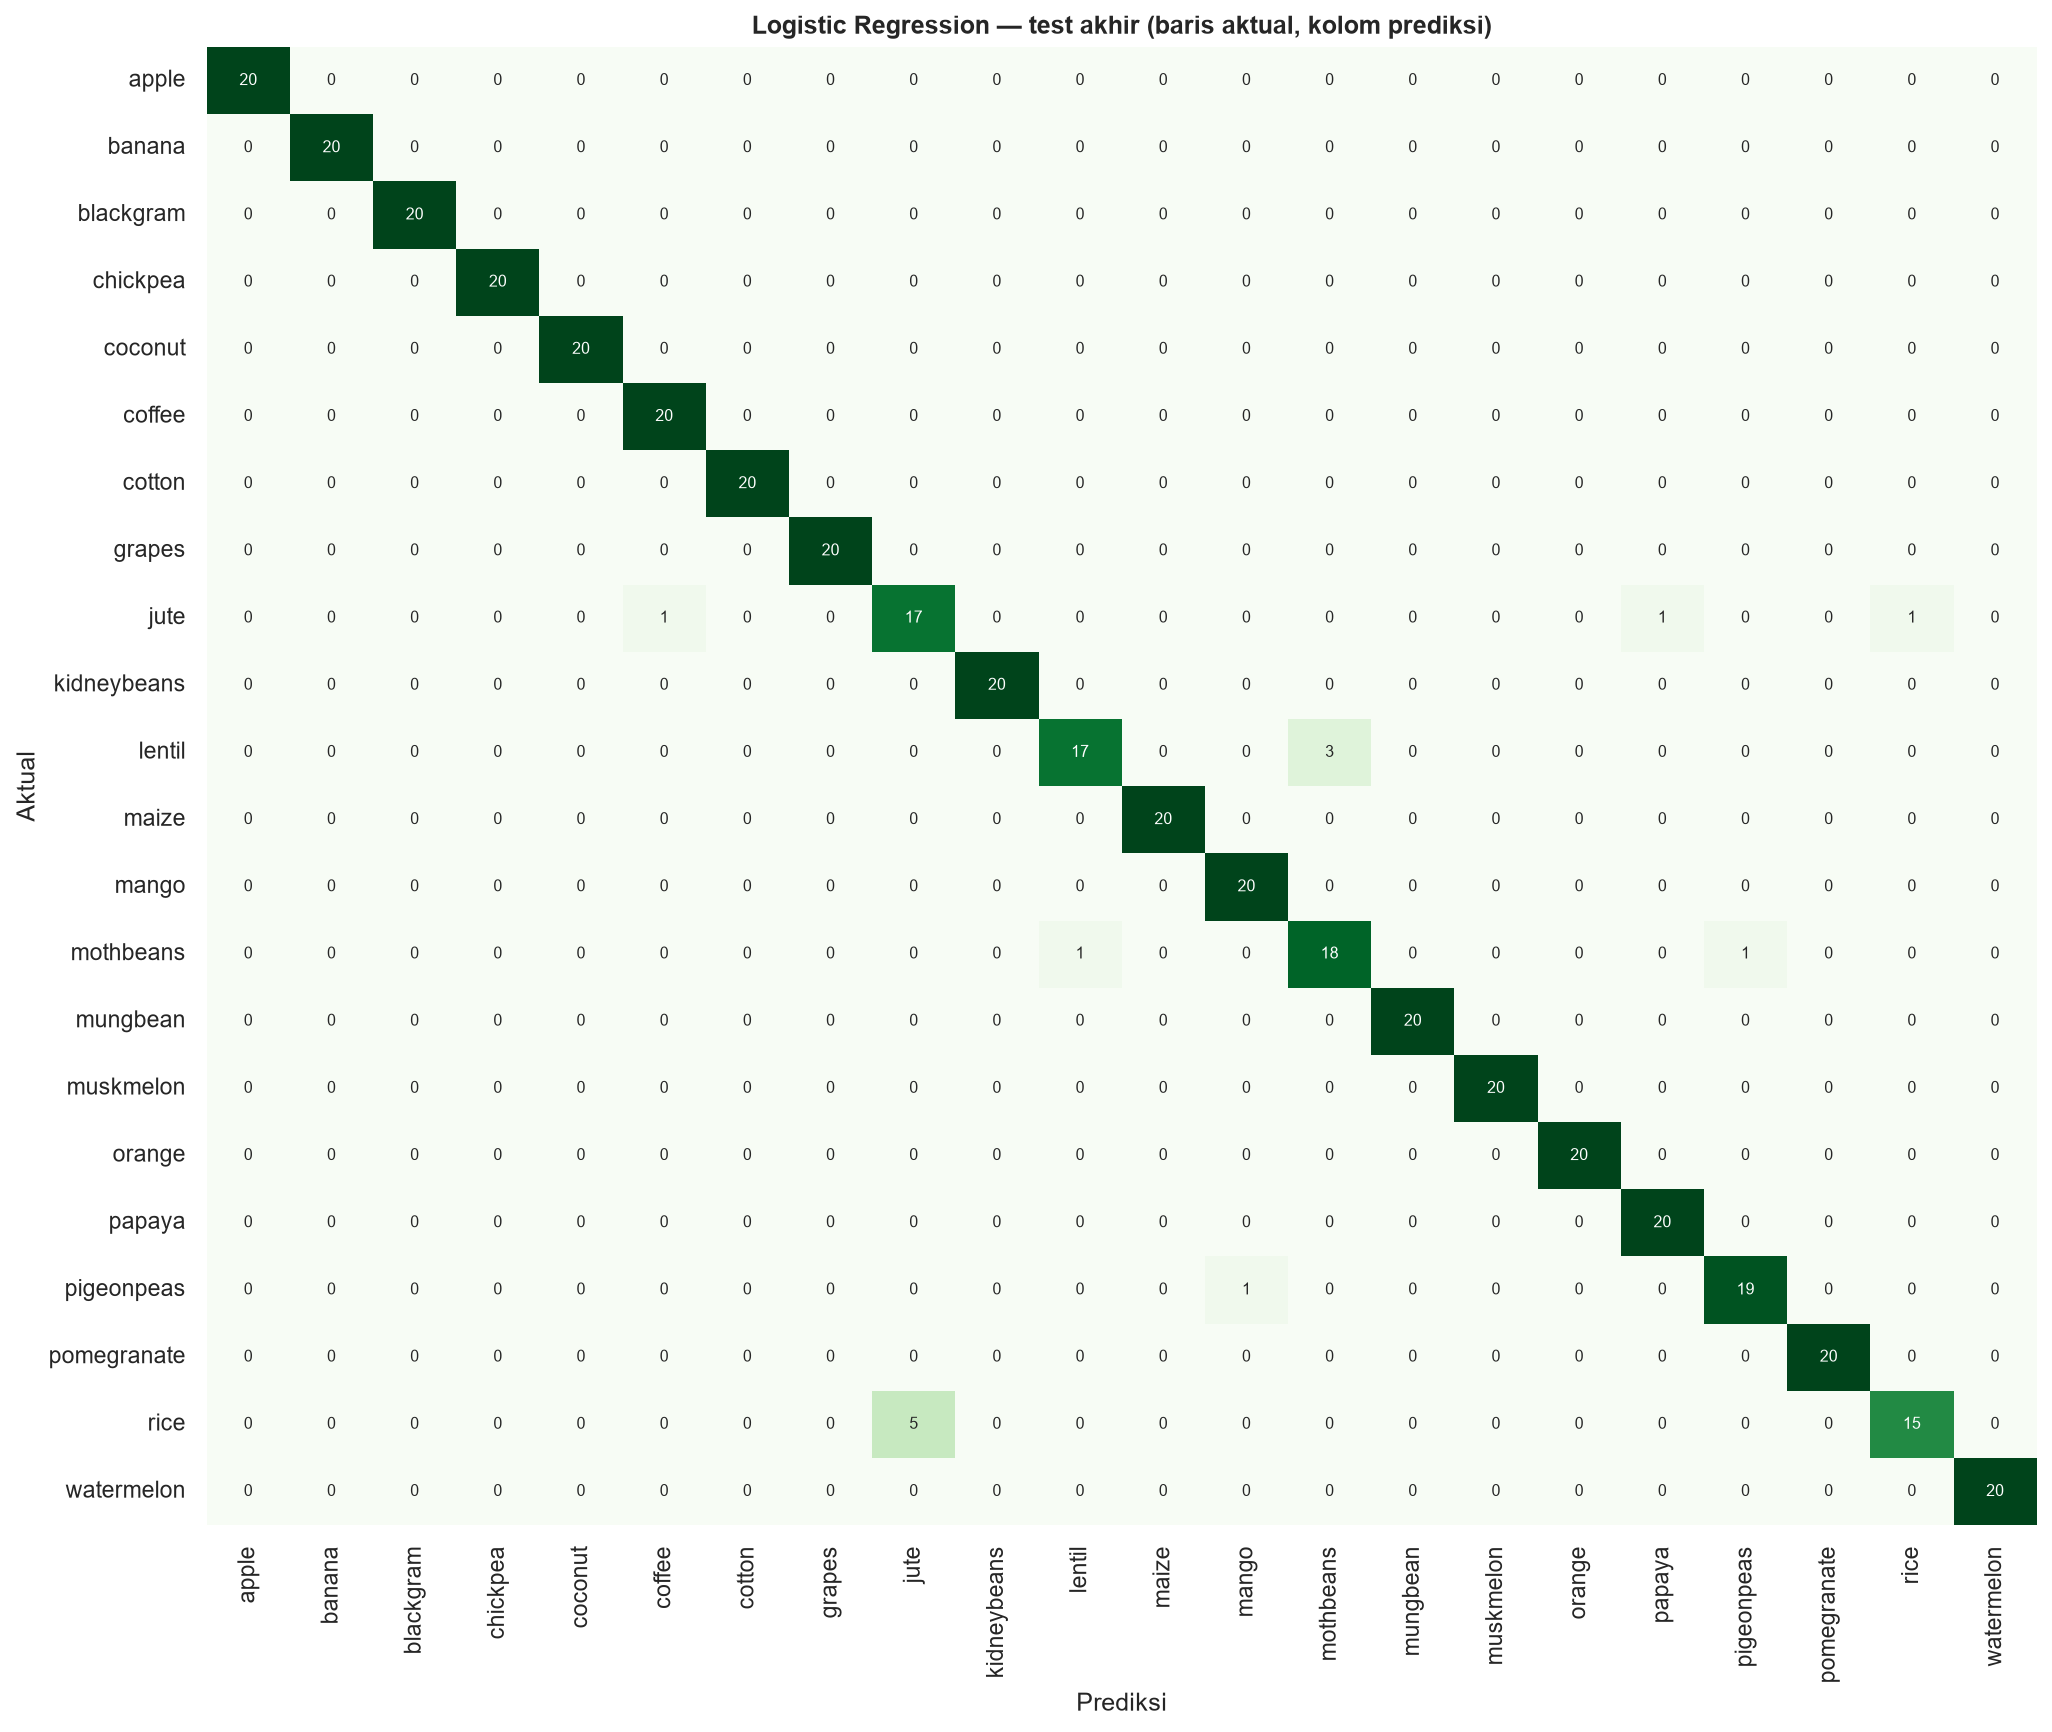

,precision,recall,f1-score,support
apple,1.000000,1.000000,1.000000,20.0
banana,1.000000,1.000000,1.000000,20.0
blackgram,1.000000,1.000000,1.000000,20.0
chickpea,1.000000,1.000000,1.000000,20.0
coconut,1.000000,1.000000,1.000000,20.0
coffee,0.952381,1.000000,0.975610,20.0
cotton,1.000000,1.000000,1.000000,20.0
grapes,1.000000,1.000000,1.000000,20.0
jute,0.772727,0.850000,0.809524,20.0
kidneybeans,1.000000,1.000000,1.000000,20.0


In [13]:
for name in ['KNN', 'Decision Tree', 'Logistic Regression']:
    display(Image(filename=str(RUN_DIR / f'plots/confusion_{name.replace(" ", "_")}.png')))
reports = read_json(RUN_DIR / 'results/classification_reports.json')
display(pd.DataFrame({k:v for k,v in reports[best].items() if isinstance(v,dict)}).T)

In [14]:
pairs = pd.read_csv(RUN_DIR / 'results/confused_pairs.csv')
errors = pd.read_csv(RUN_DIR / 'results/test_errors.csv')
display(pairs[pairs.model == best])
display(errors[errors.model == best])
means = pd.read_csv(RUN_DIR / 'results/crop_means_train.csv', index_col=0)
display(means.loc[['rice','jute','lentil','mothbeans']].round(2))

,model,actual,predicted,count
1,Logistic Regression,rice,jute,5
3,Logistic Regression,lentil,mothbeans,3
8,Logistic Regression,jute,coffee,1
9,Logistic Regression,jute,papaya,1
10,Logistic Regression,jute,rice,1
14,Logistic Regression,mothbeans,lentil,1
15,Logistic Regression,mothbeans,pigeonpeas,1
16,Logistic Regression,pigeonpeas,mango,1


,model,row_id,actual,predicted,correct,N,P,K,temperature,humidity,ph,rainfall
19,Logistic Regression,802,lentil,mothbeans,False,38.0,60.0,20.0,29.848231,60.638726,7.491217,46.804526
20,Logistic Regression,83,rice,jute,False,67.0,43.0,39.0,26.043720,84.969072,5.999969,186.753677
21,Logistic Regression,502,mothbeans,lentil,False,36.0,58.0,25.0,28.660242,59.318912,8.399136,36.926297
22,Logistic Regression,521,mothbeans,pigeonpeas,False,22.0,49.0,22.0,28.234947,61.562052,3.711059,72.666664
23,Logistic Regression,98,rice,jute,False,78.0,35.0,44.0,26.543481,84.673536,7.072656,183.622266
24,Logistic Regression,35,rice,jute,False,95.0,55.0,42.0,26.795339,82.148087,5.950661,193.347399
25,Logistic Regression,2013,jute,papaya,False,60.0,55.0,40.0,24.994996,88.956928,7.027780,151.493563
26,Logistic Regression,837,lentil,mothbeans,False,18.0,57.0,21.0,27.376596,63.939278,6.155916,49.473718
27,Logistic Regression,2012,jute,rice,False,89.0,41.0,38.0,23.128444,74.683227,6.344752,199.836291
28,Logistic Regression,2005,jute,coffee,False,100.0,35.0,36.0,25.310423,72.013644,6.346715,190.557762


,N,P,K,temperature,humidity,ph,rainfall
label,,,,,,,
rice,80.06,47.79,39.98,23.61,82.25,6.44,239.80
jute,78.66,47.05,39.79,24.85,80.14,6.76,175.35
lentil,18.66,68.25,19.55,24.13,64.78,6.92,45.64
mothbeans,20.74,47.88,20.26,28.14,53.02,6.80,51.05


**Interpretasi:** kemiripan sejumlah NPK/kelembapan pada rice dan jute membantu menjelaskan risiko tertukar, sementara hujan dapat membedakan. Lihat angka contoh salah untuk menguji dugaan, bukan menganggap mean kelas penyebab pasti. Detail nested out-of-fold juga tersedia dan bukan prediksi in-sample.

In [15]:
oof = pd.read_csv(RUN_DIR / 'results/oof_predictions.csv')
display(oof.groupby('model').correct.agg(['mean','count']))
display(oof[(oof.model == best) & (~oof.correct)].head(15))

,mean,count
model,,
Decision Tree,0.985227,1760
KNN,0.982386,1760
Logistic Regression,0.985227,1760


,model,fold,row_id,actual,predicted,correct
3558,Logistic Regression,1,538,mothbeans,pomegranate,False
3559,Logistic Regression,1,1971,cotton,maize,False
3688,Logistic Regression,1,65,rice,jute,False
3701,Logistic Regression,1,570,mothbeans,lentil,False
3767,Logistic Regression,1,78,rice,jute,False
3959,Logistic Regression,2,571,mothbeans,lentil,False
4020,Logistic Regression,2,87,rice,jute,False
4064,Logistic Regression,2,2004,jute,rice,False
4124,Logistic Regression,2,73,rice,jute,False
4144,Logistic Regression,2,2025,jute,rice,False


## 10. Fitur DT dan overfitting
Importance DT bukan penjelasan lokal LR dan bukan bukti pentingnya fitur terhadap hasil panen. Fitur berkorelasi dapat saling menggantikan.

,feature,importance
0,rainfall,0.368306
1,humidity,0.223874
2,P,0.210276
3,K,0.093773
4,temperature,0.050333
5,N,0.046300
6,ph,0.007138


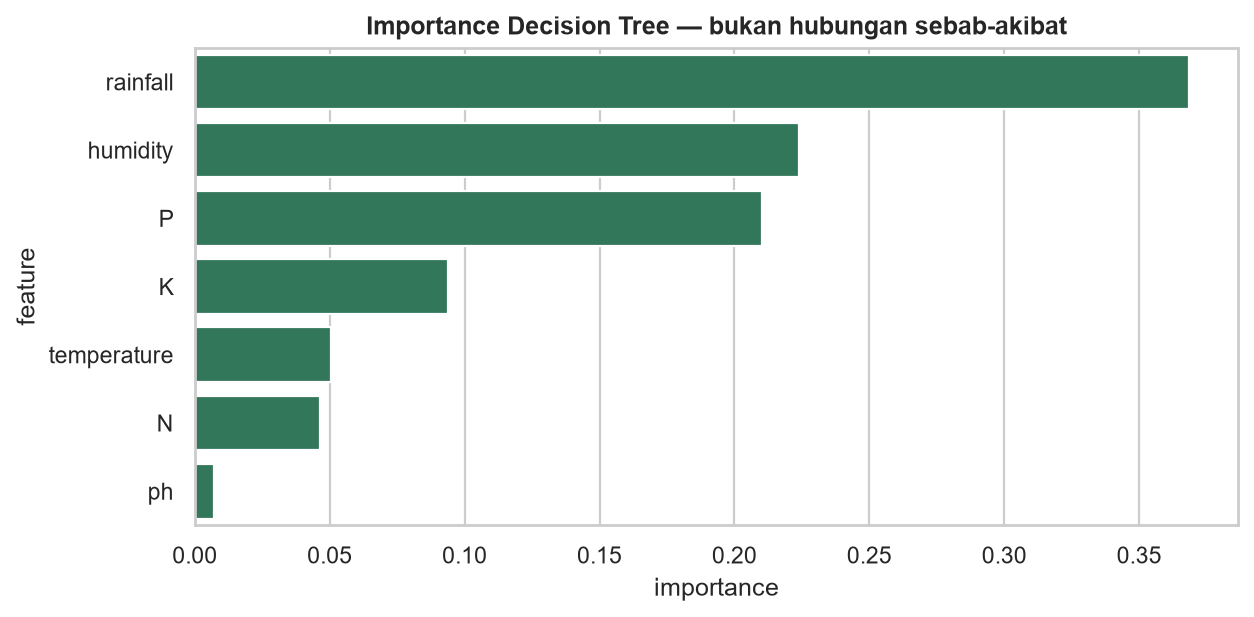

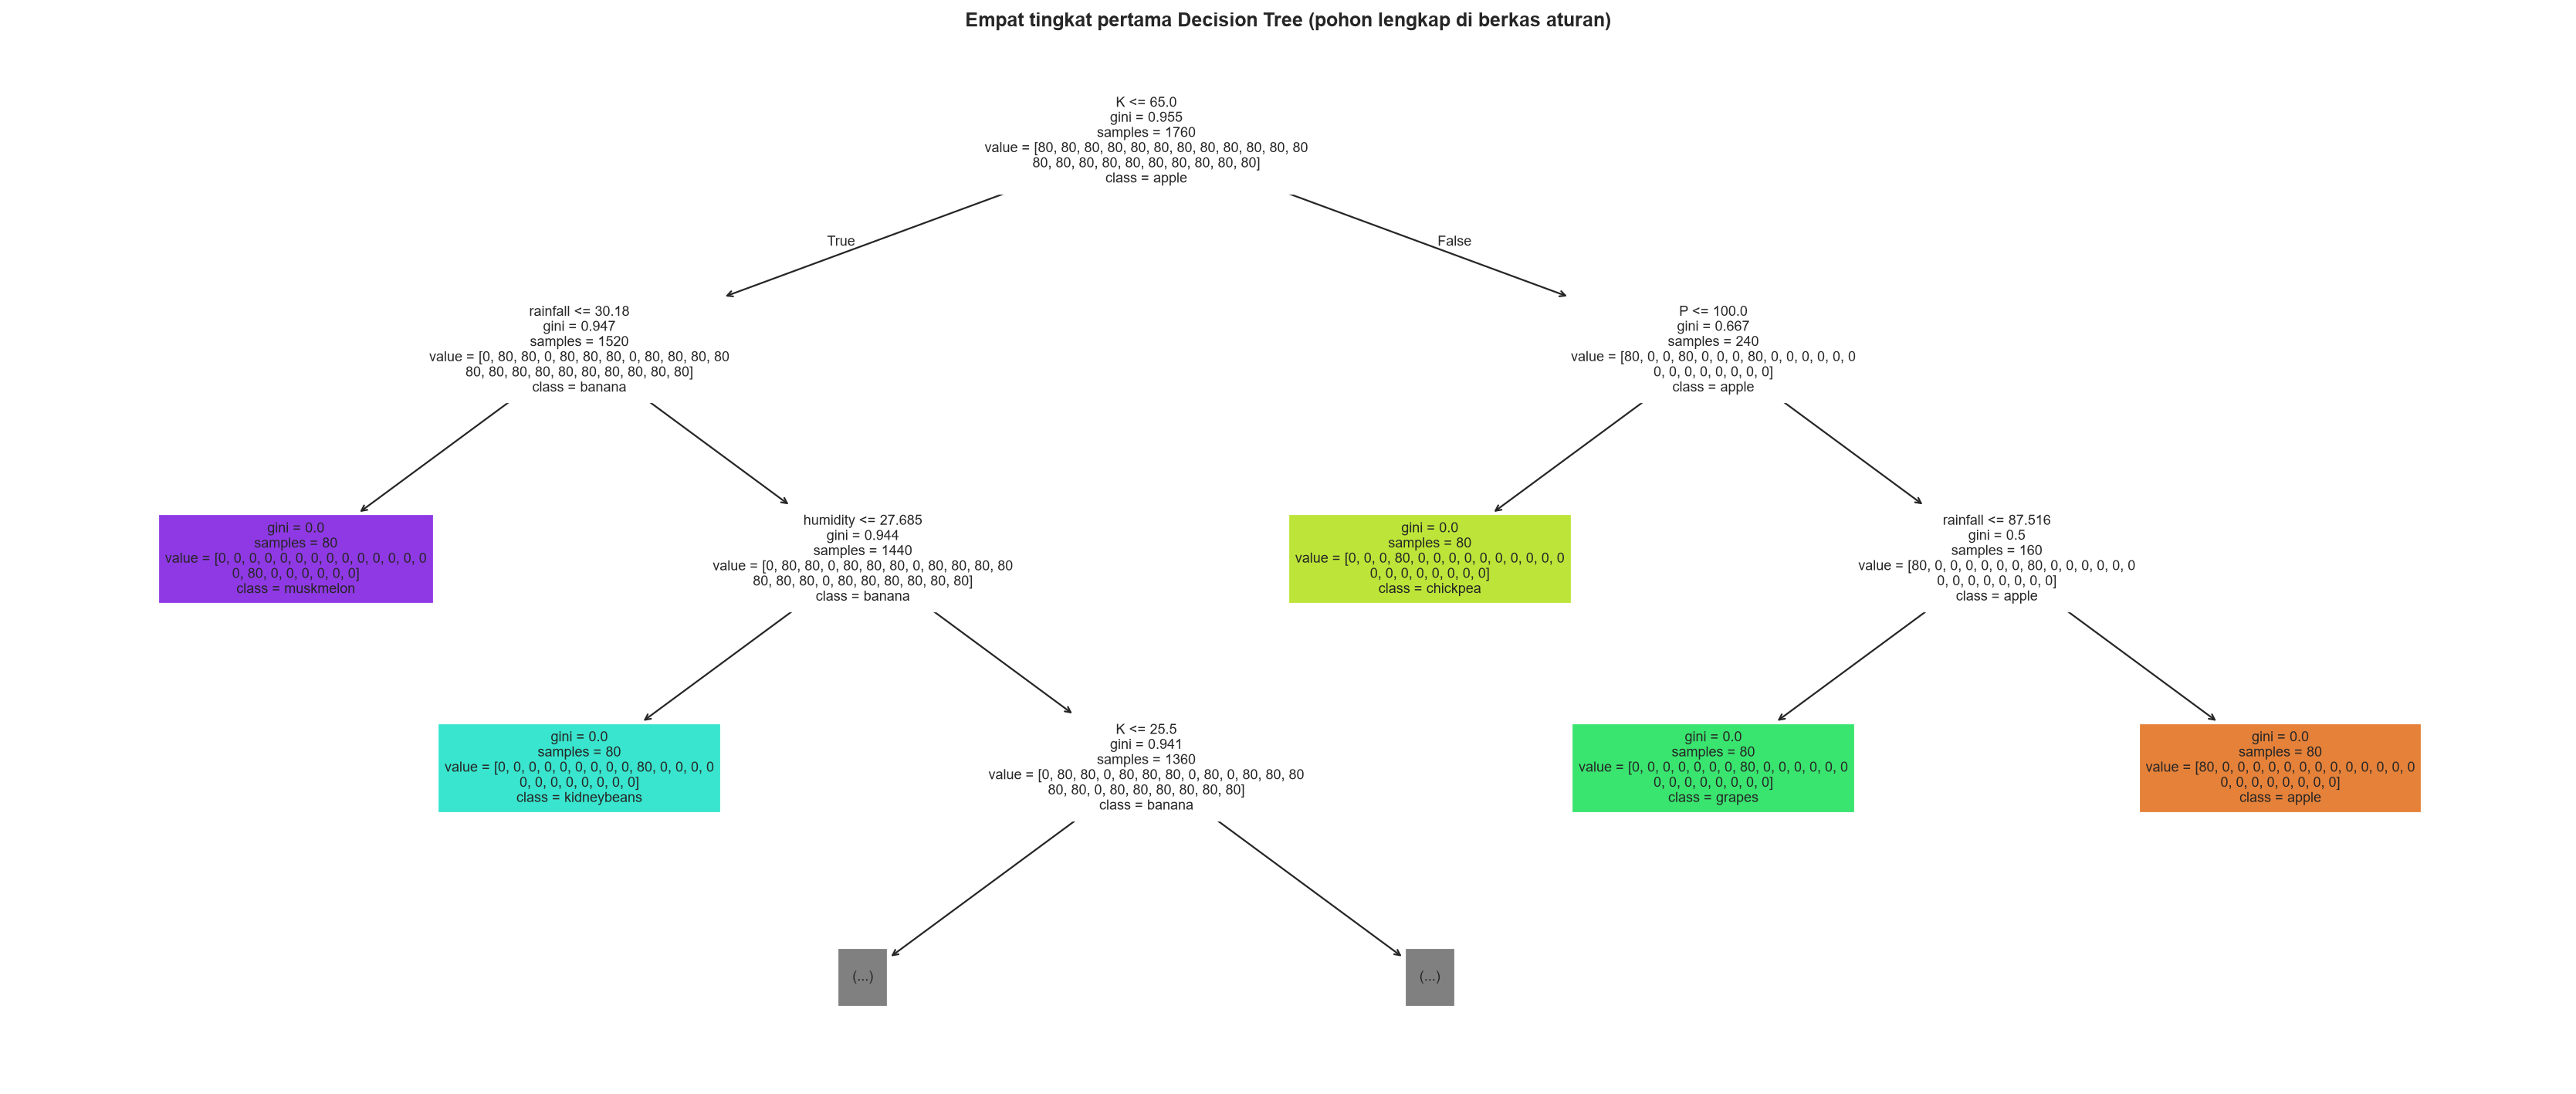

In [16]:
display(pd.read_csv(RUN_DIR / 'results/feature_importance_dt.csv'))
display(Image(filename=str(RUN_DIR / 'plots/feature_importance.png')))
display(Image(filename=str(RUN_DIR / 'plots/pohon_ringkas.png')))

## 11. Percobaan scaling sebelum/sesudah
Setting tetap KNN k=5 dan DT depth=8; CV training yang sama, bukan test. DT final hasil tuning berbeda dari DT ablation depth=8.

,model,scaling,cv_f1_macro_mean,cv_f1_macro_std,setting
0,KNN,False,0.978498,0.008579,k=5
1,KNN,True,0.971448,0.007508,k=5
2,Decision Tree,False,0.804530,0.040545,max_depth=8
3,Decision Tree,True,0.804530,0.040545,max_depth=8


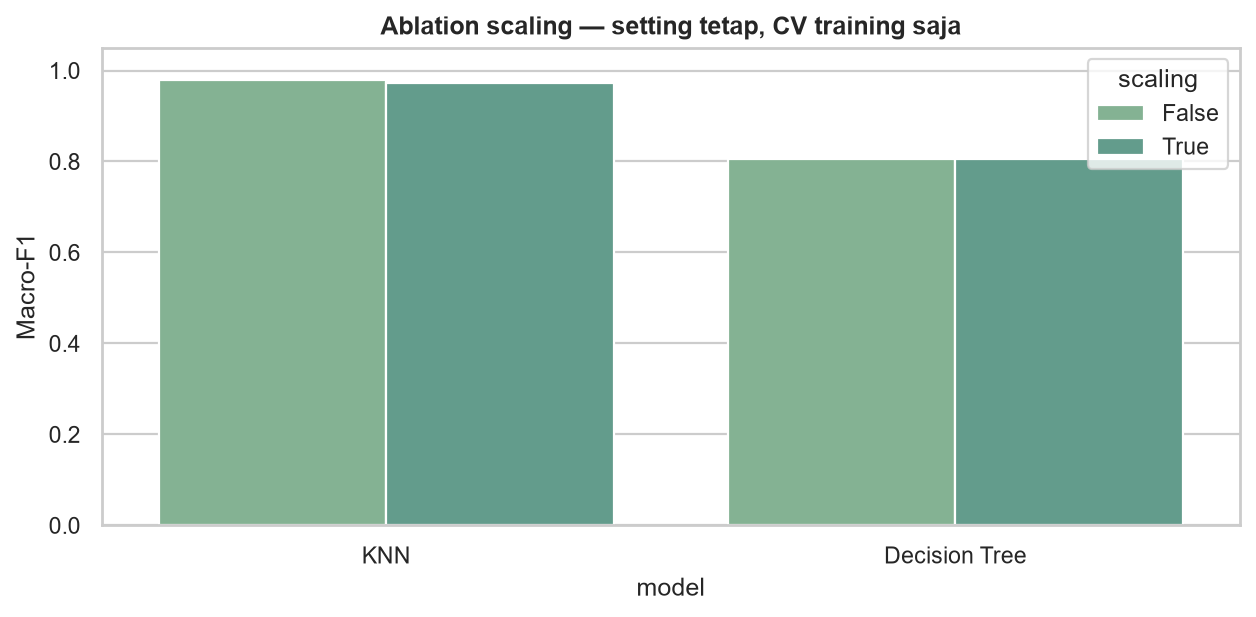

In [17]:
scaling = pd.read_csv(RUN_DIR / 'results/scaling_experiment.csv')
display(scaling)
display(Image(filename=str(RUN_DIR / 'plots/scaling.png')))

**Interpretasi aktual:** scaling menurunkan skor KNN k=5 pada eksperimen ini; jangan menyembunyikan hasil. Scaling tetap mengatasi ketergantungan terhadap skala mentah, bukan menjamin skor naik. DT ablation menghasilkan skor sama; depth=8 dapat terlalu dangkal untuk 22 kelas. KNN tanpa scaling bukan kandidat pemilihan utama dalam rancangan ini.

## 12. Simpan/muat model dan prediksi input baru
Bundle sudah tersimpan oleh run_training: pipeline + label encoder + urutan fitur + rentang/profil training. Hanya muat joblib lokal tepercaya.

In [18]:
import joblib
bundle = joblib.load(RUN_DIR / 'models/crop_bundle.joblib')
example = pd.read_csv(RUN_DIR / 'examples/contoh_batch.csv').head(3)
result, probabilities = predict_frame(example, bundle)
display(result)
display(probabilities)
assert np.allclose(probabilities.sum(axis=1), 1)
print('Artefak audit disimpan:', RUN_DIR / 'models/crop_bundle.joblib')

,N,P,K,temperature,humidity,ph,rainfall,rekomendasi,nama_tanaman,top_1,skor_1,top_2,skor_2,top_3,skor_3
0,12.0,129.0,205.0,22.362383,91.157616,6.119432,118.683273,apple,Apel,apple,0.999634,papaya,0.000225,grapes,0.000141
1,100.0,74.0,52.0,25.434805,81.539778,5.837258,96.478004,banana,Pisang,banana,0.999793,jute,0.000105,cotton,0.000089
2,50.0,55.0,16.0,28.814607,65.335381,7.581443,62.262425,blackgram,Black gram,blackgram,0.912051,mothbeans,0.069840,maize,0.007370


,apple,banana,blackgram,chickpea,coconut,coffee,cotton,grapes,jute,kidneybeans,...,mango,mothbeans,mungbean,muskmelon,orange,papaya,pigeonpeas,pomegranate,rice,watermelon
0,9.996343e-01,4.418021e-16,1.339255e-15,2.798652e-18,3.631956e-27,1.606227e-45,5.462596e-41,1.410393e-04,1.126718e-18,1.635583e-41,...,2.452266e-35,2.044737e-47,2.196569e-33,7.057136e-39,3.879757e-51,2.246432e-04,8.194823e-24,9.596598e-14,7.760283e-37,4.371572e-22
1,5.541540e-09,9.997934e-01,4.109895e-06,1.904811e-14,1.309143e-17,3.065886e-11,8.869036e-05,9.391022e-10,1.047685e-04,1.361631e-21,...,5.040009e-19,9.842292e-22,6.415741e-14,4.740497e-13,1.768853e-17,1.991004e-06,2.685177e-10,3.741499e-13,1.666554e-11,2.576588e-06
2,4.506840e-13,1.751917e-07,9.120509e-01,4.896335e-08,1.535072e-13,1.884612e-06,3.049386e-07,1.638869e-07,1.369613e-04,1.072679e-10,...,1.687550e-05,6.984024e-02,3.448331e-03,1.241612e-09,4.537347e-04,1.489193e-07,2.916812e-04,3.635686e-06,4.153054e-14,5.519820e-08


Artefak audit disimpan: C:\Users\user\AppData\Local\Temp\opencode\crop_notebook_lxhdmgn3\models\crop_bundle.joblib


## 13. Audit konsistensi terhadap paket utama
Model aplikasi tidak direfit dengan test; hasil eksperimen dari kode yang sama seharusnya identik pada environment ini.

In [19]:
main_cv = pd.read_csv(root / 'results/cv_comparison.csv')
main_test = pd.read_csv(root / 'results/test_comparison.csv')
pd.testing.assert_frame_equal(cv, main_cv, check_exact=False, rtol=1e-10)
pd.testing.assert_frame_equal(test, main_test, check_exact=False, rtol=1e-10)
assert summary['selected_model'] == read_json(root / 'results/summary.json')['selected_model']
print('Konsisten: CV, test, dan model terpilih.')

Konsisten: CV, test, dan model terpilih.


## 14. Implementasi dan batasan
Jalankan `python -m streamlit run app.py`. Aplikasi tidak fit model pada input pengguna, memeriksa skema angka, memberi peringatan rentang dan menampilkan skor tiga kelas. Skor bukan peluang panen; kondisi training bukan kondisi ideal agronomis.

Dataset terkait India dan literatur menyebut augmentasi; protokol asli, satuan NPK, periode hujan serta ketergantungan antarsampel belum terverifikasi. Tidak ada hasil panen, harga, hama, varietas, lokasi/waktu. Validasi eksternal Indonesia masih diperlukan. Selisih CV yang tipis bukan bukti keunggulan signifikan.

## 15. Referensi
- [R1] Thilakarathne, N. N.; Bakar, M. S. A.; Abas, P. E.; Yassin, H. (2022). A Cloud Enabled Crop Recommendation Platform for Machine Learning-Driven Precision Farming. https://doi.org/10.3390/s22166299
- [R2] Shastri, S.; Kumar, S.; Mansotra, V.; Salgotra, R. (2025). Advancing crop recommendation system with supervised machine learning and explainable artificial intelligence. https://doi.org/10.1038/s41598-025-07003-8
- [R3] Singh, G.; Sharma, S. (2025). Enhancing precision agriculture through cloud based transformative crop recommendation model. https://doi.org/10.1038/s41598-025-93417-3
- [R4] Venkateswara, S. M.; Padmanaban, J. (2025). Interpretable deep learning models for independent fertilizer and crop recommendation. https://doi.org/10.1038/s41598-025-26910-4
- [R5] Dhingra, B.; Agarwal, S.; Gupta, R. (2026). KRISHI.AI: an explainable machine learning framework for data-driven crop recommendation. https://doi.org/10.1038/s41598-026-68815-w

Lihat `references/Tabel_Studi_Literatur.md` untuk masalah, dataset, metode, metrik, hasil dan perbedaan tiap artikel.

In [20]:
audit.cleanup()
print('Folder audit sementara dibersihkan; output notebook tetap tertanam dan model utama tidak berubah.')

Folder audit sementara dibersihkan; output notebook tetap tertanam dan model utama tidak berubah.
